# Cruce EQ ↔ energía - Baterías equivalentes contra consumo

**Objetivo.** Juntar por primera vez las dos mitades del indicador de intensidad: las
**baterías equivalentes (EQ)** que calcula la base de datos (`gold.v_resumen_equ_diario`,
a través del servicio `BatterySeries`) y la **energía** de las hojas de la planta y del
SCADA de los rectificadores. El indicador es siempre una razón de sumas:

> **kWh por EQ = Σ kWh / Σ EQ** del mismo periodo (nunca el promedio de razones diarias o mensuales).

**Qué no se repite aquí.** La limpieza y los hallazgos del lado de energía ya están en
`eda_fa.ipynb` (reparto fijo 85/15, ceros falsos, tarifa) y en `eda_rectificadores.ipynb`
(contadores en Wh, resolución de 2 kWh, contador congelado de R2, rectificadores ≈ 99 % de
F&A en julio). Este notebook **reutiliza** esa lógica y solo agrega lo nuevo:

1. El lado EQ: rango disponible y huecos.
2. Pareo mensual: F&A, OREC y ENSAMBLE.
3. Pareo diario (jul-sep 2026): rectificadores contra FORMACION + DECORADO, con razón móvil de 7 días y revisión de rezago.
4. Contraste de la columna `Produccion (Equivalente)` del libro contra nuestras EQ.
5. Razones por año fiscal.

**Convención.** El código está en inglés (regla del repositorio); el texto, en español, como
los demás EDA.

## 0. Conexión a la base de datos desde el equipo

La base de datos **no publica ningún puerto** (solo Caddy lo hace) y el `DATABASE_URL` del
`.env` apunta al host `db`, que solo existe dentro de Docker. Para leer desde este notebook se
levanta un **relé temporal** (socat) en la red interna de Docker, escuchando solo en
`127.0.0.1:5433`. No cambia ningún archivo del repositorio.

**Antes de ejecutar** (con `make up` ya arriba):

```bash
docker run --rm -d --name db-tunnel --network clarios-energy_backend \
  -p 127.0.0.1:5433:5432 alpine/socat \
  tcp-listen:5432,fork,reuseaddr tcp-connect:db:5432
```

**Al terminar:**

```bash
docker rm -f db-tunnel
```

La contraseña se lee del `.env` con `python-dotenv` y **nunca** se escribe en el notebook.
Se usa `127.0.0.1` y no `localhost` (con `localhost` cada conexión prueba primero IPv6 y se
demora). La sesión es de **solo lectura** (`default_transaction_read_only=on`).

In [1]:
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import dotenv_values
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sqlalchemy.exc import OperationalError

from energy.domain.equs_gold import DateRange
from energy.domain.equs_series import BatteryEquivalents, totals
from energy.pipelines.flows.equs_gold import battery_equivalents

REPO_ROOT = Path.cwd().parent

# Real filenames in data/ (the older notebooks still name them differently).
ENERGY_WORKBOOK = REPO_ROOT / "data" / "Base_de_datos.xlsx"
RECTIFIER_WORKBOOK = REPO_ROOT / "data" / "SCADA-Base de datos F&A.xlsx"
RECTIFIER_SHEET = "Dataset 1"

RELAY_HOST, RELAY_PORT = "127.0.0.1", 5433
EQ_RANGE = DateRange(date(2025, 10, 1), date(2026, 9, 30))  # FY26, all the EQ the database holds

LOCAL_TZ = "America/Bogota"  # SCADA timestamps are naive local time (UTC-5, no DST)
WH_PER_KWH = 1000
OPERATING_KWH = 50  # below this in an hour, a rectifier counts as off
PHYSICAL_LIMIT_FACTOR = 2  # a jump above 2 x p99 of operating hours is impossible
RECTIFIERS = {"RECTIFICADOR 1": "R1", "RECTIFICADOR 2": "R2", "RECTIFICADOR 3": "R3"}
ROLLING_DAYS = 7
LAGS = range(-2, 3)
CENT = 0.01

SPANISH_MONTHS = {
    "Ene": 1, "Feb": 2, "Mar": 3, "Abr": 4, "May": 5, "Jun": 6,
    "Jul": 7, "Ago": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dic": 12,
}  # fmt: skip
WEEKDAYS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
SUNDAY = 6

# Energy pair -> (sheet of Base_de_datos, its total row, the EQUS processes it is set against)
PAIRS = {
    "F&A": ("F&A", "F&A", ("FORMACION", "DECORADO")),
    "OREC": ("OREC", "OREC", ("OREC",)),
    "ENSAMBLE": ("Ensamble", "Ensamble", ("ENSAMBLE",)),
}

# The SCADA export has no default style; openpyxl warns about it on every read.
warnings.filterwarnings("ignore", message="Workbook contains no default style")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)

### Funciones copiadas de otros notebooks

Copias **sin cambios de lógica** (solo los nombres pasan al inglés) para no reescribirlas:

| Función aquí | Original | Notebook |
|---|---|---|
| `fiscal_year`, `fiscal_month`, `fy_label` | `anio_fiscal`, `mes_fiscal`, `etiqueta_fy` | `eda_rc_energia.ipynb`, celdas 4 y 6 |
| `hourly_consumption` | cálculo de `consumo` | `eda_rectificadores.ipynb`, celda 15 |
| `zero_runs` | `rachas_en_cero` | `eda_rectificadores.ipynb`, celda 25 |
| `spread_frozen_jumps` | reparto del salto (`train_corr`) | `eda_rectificadores.ipynb`, celda 29 |

Un cambio deliberado: allá el límite físico (2 × p99) se ajustó solo con *train*; aquí no se
entrena ningún modelo, así que se calcula con toda la serie jul-oct.

In [2]:
# --- Copied from eda_rc_energia.ipynb (cells 4 and 6) -------------------------------
FY_START_MONTH = 10  # FY26 = Oct 2025 ... Sep 2026, named by the year it ends


def fiscal_year(dates: pd.DatetimeIndex) -> pd.Index:
    """Oct 2025 ... Sep 2026 -> 2026 (FY26)."""
    return dates.year + (np.asarray(dates.month) >= FY_START_MONTH).astype(int)


def fiscal_month(dates: pd.DatetimeIndex) -> np.ndarray:
    """Position of the month in its fiscal year: 1 = October ... 12 = September."""
    return (np.asarray(dates.month) - FY_START_MONTH) % 12 + 1


def fy_label(years: pd.Index | list[int]) -> list[str]:
    """2026 -> 'FY26'."""
    return [f"FY{int(year) % 100:02d}" for year in years]


# --- Copied from eda_rectificadores.ipynb (cells 15, 25 and 29) ----------------------
def hourly_consumption(counters: pd.DataFrame) -> pd.DataFrame:
    """Return the kWh of each interval between readings, labelled by the reading that starts it."""
    hourly = ((counters.shift(-1) - counters).iloc[:-1] / WH_PER_KWH).astype("float64")
    hourly.index.name = "start"
    return hourly


def zero_runs(series: pd.Series) -> pd.DataFrame:
    """Runs of consecutive zero hours, with the kWh of the hour right after each run."""
    is_zero = series.eq(0)
    gap = series.index.to_series().diff().ne(pd.Timedelta(hours=1))
    group = (is_zero.ne(is_zero.shift()) | gap).cumsum()
    rows = []
    for _, block in series[is_zero].groupby(group[is_zero]):
        following = block.index[-1] + pd.Timedelta(hours=1)
        rows.append(
            {
                "start": block.index[0],
                "end": block.index[-1],
                "hours": len(block),
                "kwh_next_hour": series.get(following, np.nan),
            }
        )
    return pd.DataFrame(rows, columns=["start", "end", "hours", "kwh_next_hour"])


def spread_frozen_jumps(hourly: pd.DataFrame, frozen: pd.DataFrame) -> pd.DataFrame:
    """Spread each jump over its frozen hours, shaped like the other rectifiers; energy is kept."""
    corrected = hourly.copy()
    for _, run in frozen.iterrows():
        rectifier = run["rectifier"]
        hours = pd.date_range(run["start"], run["end"] + pd.Timedelta(hours=1), freq="h")
        energy = corrected.loc[hours, rectifier].sum()
        weights = hourly.loc[hours, [r for r in hourly.columns if r != rectifier]].mean(axis=1)
        corrected.loc[hours, rectifier] = energy * weights / weights.sum()
    return corrected

In [3]:
env = dotenv_values(REPO_ROOT / ".env")
engine = create_engine(
    URL.create(
        "postgresql+psycopg",
        username=env["POSTGRES_USER"],
        password=env["POSTGRES_PASSWORD"],
        host=RELAY_HOST,
        port=RELAY_PORT,
        database=env["POSTGRES_DB"],
    ),
    connect_args={"options": "-c default_transaction_read_only=on"},
)
try:
    with engine.connect() as connection:
        head = connection.execute(text("SELECT version_num FROM alembic_version")).scalar_one()
        read_only = connection.execute(text("SHOW default_transaction_read_only")).scalar_one()
except OperationalError as error:
    raise RuntimeError(
        f"No database on {RELAY_HOST}:{RELAY_PORT}: start the relay (see the cell above)"
    ) from error
print(f"Connected through the relay: Alembic head {head}, read-only = {read_only}")

Connected through the relay: Alembic head 0006, read-only = on


## 1. Lado EQ: rango disponible y huecos

Las EQ salen del servicio `BatterySeries` (el mismo de `make daily`): solo las cuentas que
suman a EQUS BATT, por día contable (`fecha_efectiva`), con la versión de la ecuación vigente
en cada mes. La serie diaria trae además la conciliación: los días de cada mes completo deben
sumar exactamente `gold.v_resumen_equ`.

In [4]:
def series_frame(series: BatteryEquivalents) -> pd.DataFrame:
    """One row per day (or month): EQ of each battery process and EQUS BATT, as floats."""
    frame = pd.DataFrame(
        [{"period": t.start, **t.by_process, "EQUS BATT": t.total} for t in totals(series)]
    ).set_index("period")
    frame.index = pd.to_datetime(frame.index)
    return frame.astype("float64")


daily_series = battery_equivalents(EQ_RANGE, frequency="day", engine=engine)
monthly_series = battery_equivalents(EQ_RANGE, frequency="month", engine=engine)
eq_daily = series_frame(daily_series)
eq_monthly = series_frame(monthly_series)
days_with_rows = pd.DatetimeIndex(sorted({row.start for row in daily_series.rows}))

print(f"Range asked: {EQ_RANGE.start} to {EQ_RANGE.end} ({len(eq_daily)} days)")
print(f"Days with EQ rows: {len(days_with_rows)}, first {days_with_rows[0]:%Y-%m-%d}, "
      f"last {days_with_rows[-1]:%Y-%m-%d}")  # fmt: skip
print(f"Whole months reconciled against gold.v_resumen_equ: {len(daily_series.reconciled_months)}, "
      f"driver-months that differ: {len(daily_series.mismatches)}")  # fmt: skip
print(f"EQUS BATT FY26: {eq_daily['EQUS BATT'].sum():,.2f}")

Range asked: 2025-10-01 to 2026-09-30 (365 days)
Days with EQ rows: 325, first 2025-10-01, last 2026-09-30
Whole months reconciled against gold.v_resumen_equ: 12, driver-months that differ: 0
EQUS BATT FY26: 2,310,723.60


In [5]:
zero_days = eq_daily.index[eq_daily["EQUS BATT"] == 0]
by_weekday = (
    pd.Series(zero_days.dayofweek)
    .map(dict(enumerate(WEEKDAYS)))
    .value_counts()
    .reindex(WEEKDAYS, fill_value=0)
)
display(by_weekday.rename("days with EQUS BATT = 0").to_frame().T)

not_sunday = zero_days[zero_days.dayofweek != SUNDAY]
print(
    "Zero days that are not Sundays:",
    [f"{d:%Y-%m-%d} ({WEEKDAYS[d.dayofweek]})" for d in not_sunday],
)

coverage = pd.DataFrame(
    {
        "days_in_month": eq_daily.groupby(eq_daily.index.to_period("M")).size(),
        "days_with_eq": (eq_daily["EQUS BATT"] != 0).groupby(eq_daily.index.to_period("M")).sum(),
    }
)
coverage["days_without_eq"] = coverage["days_in_month"] - coverage["days_with_eq"]
display(coverage.T)

period,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
days with EQUS BATT = 0,1,1,1,3,1,1,32


Zero days that are not Sundays: ['2025-12-25 (Jue)', '2025-12-30 (Mar)', '2025-12-31 (Mié)', '2026-01-01 (Jue)', '2026-03-23 (Lun)', '2026-04-02 (Jue)', '2026-04-03 (Vie)', '2026-04-04 (Sáb)']


period,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
days_in_month,31,30,31,31,28,31,30,31,30,31,31,30
days_with_eq,28,26,24,27,26,25,23,26,30,31,29,30
days_without_eq,3,4,7,4,2,6,7,5,0,0,2,0


**Cómo leerlo.** Un día con EQ = 0 no se distingue, desde la base de datos, de un día cuya
exportación faltó. Si los ceros caen en domingos y festivos, son paradas reales; un cero en
día hábil sería un posible hueco de datos a revisar con la planta.

## 2. Pareo mensual: energía de la planta contra EQ

Energía: `Base_de_datos.xlsx`, fila **total** de cada hoja (`F&A`, `OREC`, `Ensamble`),
columna `KWH`, que es la medición. **Nunca** `KWH por proceso`, que es un reparto fijo
(ver `eda_fa.ipynb`).

Se reutiliza la limpieza de `eda_fa.ipynb` (encabezados con espacios de más, meses en español,
números como texto) y se corrige lo que encontraron los notebooks de OREC y Ensamble: algunos
diciembres vienen rotulados con el año siguiente. Regla: **un diciembre toma el año del
noviembre que lo precede** en la hoja.

In [6]:
def read_energy_sheet(sheet: str) -> pd.DataFrame:
    """One sheet of Base_de_datos: month, process, measured kWh and the workbook's own EQ."""
    raw = pd.read_excel(ENERGY_WORKBOOK, sheet_name=sheet, header=None)
    data = raw.iloc[2:, 1:].set_axis([" ".join(str(c).split()) for c in raw.iloc[1, 1:]], axis=1)
    data = data.rename(
        columns={
            "Año": "year",
            "Mes": "month_name",
            "Proceso": "process",
            "KWH": "kwh",
            "Produccion (Equivalente)": "workbook_eq",
            "KWH/Equ (Reales)": "workbook_kwh_per_eq",
        }
    )
    data = data[pd.to_numeric(data["year"], errors="coerce").notna()].copy()
    data["year"] = pd.to_numeric(data["year"]).astype(int)
    data["process"] = data["process"].astype(str).str.strip()
    # A December takes the year of the November before it (OREC labels every December
    # with the next year; Ensamble its first one).
    november_year = data["year"].where(data["month_name"].eq("Nov")).ffill()
    is_december = data["month_name"].eq("Dic")
    data.loc[is_december, "year"] = november_year[is_december].astype(int)
    data["month"] = pd.to_datetime(
        {"year": data["year"], "month": data["month_name"].map(SPANISH_MONTHS), "day": 1}
    )
    for column in ("kwh", "workbook_eq", "workbook_kwh_per_eq"):
        data[column] = pd.to_numeric(data[column], errors="coerce")
    # False zeros (eda_fa.ipynb): KWH/Equ is 0 where production is missing.
    data.loc[data["workbook_eq"].isna(), "workbook_kwh_per_eq"] = np.nan
    return data[["month", "process", "kwh", "workbook_eq", "workbook_kwh_per_eq"]]


energy_sheets = {pair: read_energy_sheet(sheet) for pair, (sheet, _, _) in PAIRS.items()}

checks = []
for pair, (sheet, total_row, _) in PAIRS.items():
    data = energy_sheets[pair]
    total = data[data["process"] == total_row]
    calendar = pd.date_range(total["month"].min(), total["month"].max(), freq="MS")
    checks.append(
        {
            "pair": pair,
            "sheet": sheet,
            "first": f"{total['month'].min():%Y-%m}",
            "last": f"{total['month'].max():%Y-%m}",
            "months": len(total),
            "duplicated month-process": int(data.duplicated(["month", "process"]).sum()),
            "missing months": len(calendar.difference(total["month"])),
        }
    )
display(pd.DataFrame(checks).set_index("pair"))

,sheet,first,last,months,duplicated month-process,missing months
pair,,,,,,
F&A,F&A,2019-10,2026-07,82,0,0
OREC,OREC,2019-10,2026-06,81,0,0
ENSAMBLE,Ensamble,2019-10,2026-07,82,0,0


In [7]:
def monthly_pairs() -> pd.DataFrame:
    """Every month both sides have: measured kWh against our EQ, and the workbook's own EQ."""
    frames = []
    for pair, (_, total_row, processes) in PAIRS.items():
        data = energy_sheets[pair]
        total = data[data["process"] == total_row].set_index("month")
        eq = eq_monthly[list(processes)].sum(axis=1)
        joined = pd.DataFrame({"kwh": total["kwh"], "eq": eq, "workbook_eq": total["workbook_eq"]})
        joined = joined.dropna(subset=["kwh", "eq"])
        joined = joined[(joined["kwh"] > 0) & (joined["eq"] > 0)]
        frames.append(joined.assign(pair=pair))
    return pd.concat(frames).rename_axis("month").reset_index()


monthly = monthly_pairs()
monthly["kwh_per_eq"] = monthly["kwh"] / monthly["eq"]

monthly_summary = monthly.groupby("pair", sort=False).agg(
    first=("month", "min"), last=("month", "max"), months=("month", "size"),
    kwh=("kwh", "sum"), eq=("eq", "sum"), workbook_eq=("workbook_eq", "sum"),
)  # fmt: skip
monthly_summary["kwh_per_eq"] = monthly_summary["kwh"] / monthly_summary["eq"]
monthly_summary["workbook_kwh_per_eq"] = monthly_summary["kwh"] / monthly_summary["workbook_eq"]
monthly_summary["first"] = monthly_summary["first"].dt.strftime("%Y-%m")
monthly_summary["last"] = monthly_summary["last"].dt.strftime("%Y-%m")
display(monthly_summary)

display(
    monthly.pivot(index="month", columns="pair", values="kwh_per_eq")
    .reindex(columns=list(PAIRS))
    .rename(index=lambda m: f"{m:%Y-%m}")
)

,first,last,months,kwh,eq,workbook_eq,kwh_per_eq,workbook_kwh_per_eq
pair,,,,,,,,
F&A,2025-10,2026-07,10,"9,479,926.00","455,167.66","490,519.72",20.83,19.33
OREC,2025-10,2026-06,9,"3,888,712.90","582,074.99","582,074.99",6.68,6.68
ENSAMBLE,2025-10,2026-07,10,"2,265,491.00","737,795.83","737,795.83",3.07,3.07


pair,F&A,OREC,ENSAMBLE
month,,,
2025-10,20.69,6.11,2.35
2025-11,19.63,7.61,3.36
2025-12,20.88,7.03,2.87
2026-01,20.28,6.75,2.94
2026-02,20.62,6.20,2.81
2026-03,20.72,7.38,5.37
2026-04,22.38,6.02,3.81
2026-05,22.62,6.90,3.10
2026-06,19.17,6.71,2.42


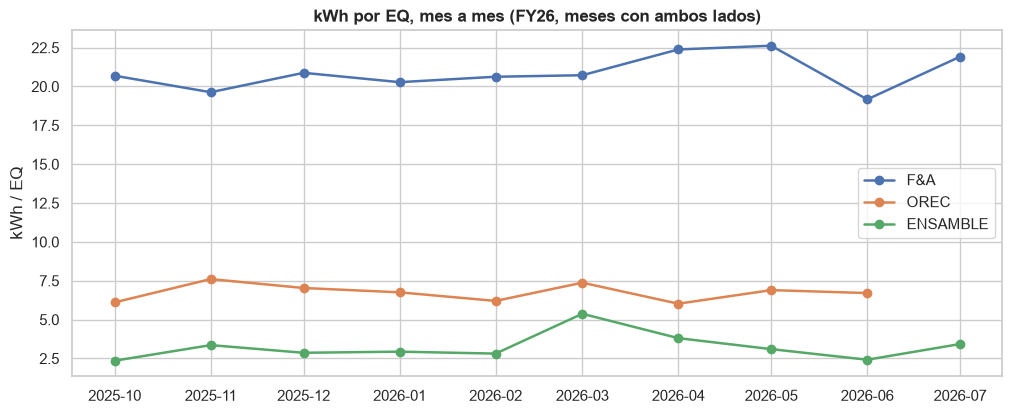

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for pair in PAIRS:
    part = monthly[monthly["pair"] == pair]
    ax.plot(part["month"], part["kwh_per_eq"], marker="o", lw=1.8, label=pair)
ax.set_title("kWh por EQ, mes a mes (FY26, meses con ambos lados)")
ax.set_ylabel("kWh / EQ")
ax.legend()
plt.show()

**Cómo leerlo.** La razón del periodo es Σ kWh / Σ EQ; la tabla mes a mes es solo para ver la
dispersión. `workbook_kwh_per_eq` usa las mismas kWh con las EQ del libro: si difiere de la
nuestra, la diferencia viene solo de las EQ (sección 4).

## 3. Pareo diario: rectificadores contra FORMACION + DECORADO (jul-sep 2026)

Se reutiliza todo el tratamiento de `eda_rectificadores.ipynb`: contadores acumulados en Wh,
consumo por intervalo, rachas en cero y reparto del salto del contador congelado.

**Frontera del día.** `fecha_efectiva` es una fecha contable local: el día D va de las 00:00 a
las 24:00 de Bogotá. Las lecturas del SCADA llegan al minuto 24:49 de cada hora, así que ningún
intervalo empieza a medianoche. Se interpola linealmente el contador acumulado (ya corregido)
en cada medianoche local: **kWh del día D = contador(D+1 00:00) − contador(D 00:00)**. Eso
reparte el intervalo de las 23:24 a las 00:24 en 35,2 y 24,8 minutos y conserva la energía.
Se compara con el método de los notebooks anteriores (cada intervalo al día en que empieza).

In [9]:
raw_readings = pd.read_excel(RECTIFIER_WORKBOOK, sheet_name=RECTIFIER_SHEET)
readings = (
    raw_readings.rename(columns={"t_stamp": "read_at", **RECTIFIERS})
    .sort_values("read_at")
    .set_index("read_at")[list(RECTIFIERS.values())]
)
hourly = hourly_consumption(readings)

operating_p99 = hourly[hourly > OPERATING_KWH].quantile(0.99)
physical_limit = operating_p99 * PHYSICAL_LIMIT_FACTOR
runs = pd.concat(
    [zero_runs(hourly[r]).assign(rectifier=r) for r in hourly.columns], ignore_index=True
)
runs["kind"] = np.where(
    runs["kwh_next_hour"] > runs["rectifier"].map(physical_limit), "frozen counter", "real stop"
)
frozen = runs[runs["kind"] == "frozen counter"]
corrected = spread_frozen_jumps(hourly, frozen)

print(f"Readings: {len(readings)}, {readings.index.min()} to {readings.index.max()}")
print("Physical limit per hour (kWh):", physical_limit.round(0).to_dict())
display(frozen)
print("Energy before and after spreading the jumps (MWh):")
display(pd.DataFrame({"before": hourly.sum() / 1000, "after": corrected.sum() / 1000}))

Readings: 2208, 2026-07-01 19:24:49.746000 to 2026-10-01 18:24:49.746000
Physical limit per hour (kWh): {'R1': 2508.0, 'R2': 2466.0, 'R3': 1360.0}


,start,end,hours,kwh_next_hour,rectifier,kind
29,2026-07-18 20:24:49.746,2026-07-22 19:24:49.746,96,"33,955.84",R2,frozen counter


Energy before and after spreading the jumps (MWh):


,before,after
R1,"1,064.76","1,064.76"
R2,"1,078.32","1,078.32"
R3,907.02,907.02


In [10]:
def daily_at_midnight(readings_index: pd.DatetimeIndex, hourly_total: pd.Series) -> pd.Series:
    """Return the kWh of each whole local day, interpolating the counter at midnight."""
    cumulative = np.r_[0.0, hourly_total.cumsum().to_numpy()]
    midnights = pd.date_range(
        readings_index[0].ceil("D"), readings_index[-1].floor("D"), freq="D"
    ).as_unit("ns")
    at_midnight = np.interp(midnights.asi8, readings_index.as_unit("ns").asi8, cumulative)
    return pd.Series(np.diff(at_midnight), index=midnights[:-1], name="kwh")


rectifier_total = corrected.sum(axis=1)
kwh_midnight = daily_at_midnight(readings.index, rectifier_total)
kwh_by_start = rectifier_total.groupby(rectifier_total.index.normalize()).sum()
kwh_by_start = kwh_by_start.reindex(kwh_midnight.index)

methods = pd.DataFrame({"midnight": kwh_midnight, "by_start": kwh_by_start})
methods["difference_pct"] = (methods["by_start"] / methods["midnight"] - 1) * 100
print(f"Whole days: {kwh_midnight.index[0]:%Y-%m-%d} to {kwh_midnight.index[-1]:%Y-%m-%d} "
      f"({len(kwh_midnight)} days)")  # fmt: skip
print(f"Total MWh, midnight vs by start: {methods['midnight'].sum() / 1000:,.1f} vs "
      f"{methods['by_start'].sum() / 1000:,.1f}")  # fmt: skip
display(methods["difference_pct"].abs().describe().to_frame("|difference| % per day").T)

Whole days: 2026-07-02 to 2026-09-30 (91 days)
Total MWh, midnight vs by start: 3,038.1 vs 3,039.1


,count,mean,std,min,25%,50%,75%,max
|difference| % per day,91.00,2.94,5.06,0.00,0.18,0.63,2.75,19.28


In [11]:
daily = pd.DataFrame(
    {
        "kwh": kwh_midnight,
        "eq_fd": eq_daily["FORMACION"] + eq_daily["DECORADO"],
        "eq_formacion": eq_daily["FORMACION"],
    }
).dropna()
daily["ratio_fd"] = daily["kwh"] / daily["eq_fd"].where(daily["eq_fd"] > 0)
daily["ratio_formacion"] = daily["kwh"] / daily["eq_formacion"].where(daily["eq_formacion"] > 0)
for target in ("fd", "formacion"):
    eq_column = "eq_fd" if target == "fd" else "eq_formacion"
    daily[f"rolling_{target}"] = (
        daily["kwh"].rolling(ROLLING_DAYS, min_periods=ROLLING_DAYS).sum()
        / daily[eq_column].rolling(ROLLING_DAYS, min_periods=ROLLING_DAYS).sum()
    )


def ratio_summary(frame: pd.DataFrame, target: str) -> dict[str, float]:
    """Period ratio, daily-ratio quantiles and the range of the rolling ratio."""
    eq_column = "eq_fd" if target == "fd" else "eq_formacion"
    daily_ratio = frame[f"ratio_{target}"].dropna()
    rolling = frame[f"rolling_{target}"].dropna()
    return {
        "period ratio (Σ/Σ)": frame["kwh"].sum() / frame[eq_column].sum(),
        "days": len(frame),
        "days with EQ = 0": int((frame[eq_column] == 0).sum()),
        "daily p10": daily_ratio.quantile(0.10),
        "daily median": daily_ratio.median(),
        "daily p90": daily_ratio.quantile(0.90),
        "daily max": daily_ratio.max(),
        "7-day min": rolling.min(),
        "7-day median": rolling.median(),
        "7-day max": rolling.max(),
    }


daily_summary = pd.DataFrame(
    {
        "FORMACION + DECORADO": ratio_summary(daily, "fd"),
        "FORMACION": ratio_summary(daily, "formacion"),
    }
)
display(daily_summary)

by_month = daily.groupby(daily.index.to_period("M")).agg(
    days=("kwh", "size"),
    kwh=("kwh", "sum"),
    eq_fd=("eq_fd", "sum"),
    eq_formacion=("eq_formacion", "sum"),
)
by_month["kwh_per_eq_fd"] = by_month["kwh"] / by_month["eq_fd"]
by_month["kwh_per_eq_formacion"] = by_month["kwh"] / by_month["eq_formacion"]
display(by_month)

,FORMACION + DECORADO,FORMACION
period ratio (Σ/Σ),20.90,38.19
days,91.00,91.00
days with EQ = 0,20.00,25.00
daily p10,17.25,32.93
daily median,20.58,36.44
daily p90,24.21,40.80
daily max,228.58,72.56
7-day min,17.32,32.78
7-day median,21.23,38.06
7-day max,43.40,102.58


,days,kwh,eq_fd,eq_formacion,kwh_per_eq_fd,kwh_per_eq_formacion
2026-07,30,"1,084,695.90","51,801.20","28,667.21",20.94,37.84
2026-08,31,"870,272.69","41,993.63","22,934.64",20.72,37.95
2026-09,30,"1,083,093.03","51,555.86","27,940.86",21.01,38.76


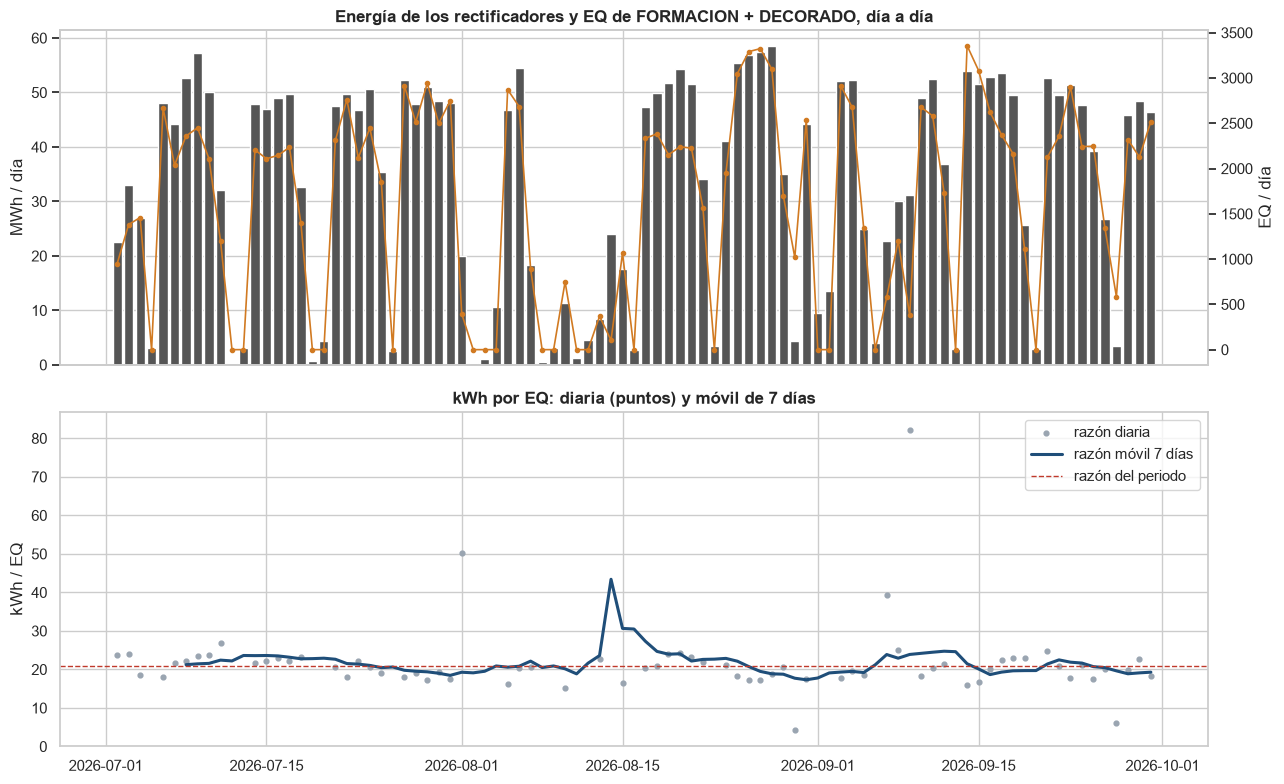

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].bar(daily.index, daily["kwh"] / 1000, color="#555555", label="rectificadores (MWh)")
axes[0].set_ylabel("MWh / día")
twin = axes[0].twinx()
twin.plot(daily.index, daily["eq_fd"], color="#d17a22", marker="o", ms=3, lw=1.2, label="EQ F+D")
twin.set_ylabel("EQ / día")
twin.grid(False)
axes[0].set_title("Energía de los rectificadores y EQ de FORMACION + DECORADO, día a día")
axes[1].scatter(daily.index, daily["ratio_fd"], s=12, color="#9aa5b1", label="razón diaria")
axes[1].plot(daily.index, daily["rolling_fd"], color="#1f4e79", lw=2.2, label="razón móvil 7 días")
axes[1].axhline(daily_summary.loc["period ratio (Σ/Σ)", "FORMACION + DECORADO"], color="#c0392b",
                ls="--", lw=1, label="razón del periodo")  # fmt: skip
axes[1].set_ylim(0, daily["rolling_fd"].max() * 2)
axes[1].set_ylabel("kWh / EQ")
axes[1].legend(loc="upper right")
axes[1].set_title("kWh por EQ: diaria (puntos) y móvil de 7 días")
plt.tight_layout()
plt.show()

### Rezago entre energía y EQ

La EQ de formación se registra cuando la batería termina de formarse, mientras que la energía
se consume durante la carga, y `fecha_efectiva` es además una fecha contable. Se mide la
correlación entre los kWh del día *t* y las EQ del día *t + k*: un máximo en *k* = +1 diría que
la producción se registra un día después del consumo.

In [13]:
lag_rows = []
for lag in LAGS:
    shifted = daily["eq_fd"].shift(-lag)
    valid = daily["kwh"].notna() & shifted.notna()
    lag_rows.append(
        {
            "lag_days (EQ of t + k)": lag,
            "pairs": int(valid.sum()),
            "pearson": daily["kwh"][valid].corr(shifted[valid]),
            "spearman": daily["kwh"][valid].corr(shifted[valid], method="spearman"),
        }
    )
lags = pd.DataFrame(lag_rows).set_index("lag_days (EQ of t + k)")
display(lags)
best_lag = int(lags["pearson"].idxmax())
print(f"Highest Pearson correlation at k = {best_lag:+d} day(s)")

,pairs,pearson,spearman
lag_days (EQ of t + k),,,
-2,89,-0.01,0.01
-1,90,0.42,0.43
0,91,0.96,0.91
1,90,0.40,0.39
2,89,-0.01,-0.03


Highest Pearson correlation at k = +0 day(s)


## 4. Contraste: `Produccion (Equivalente)` del libro contra nuestras EQ

La columna `Produccion (Equivalente)` de `Base_de_datos.xlsx` debería ser la columna H de
RESUMEN EQU del libro EQUS BATT. Nuestras EQ difieren del libro en dos cuentas, a propósito
(`docs/equs_calculation_explained.md`):

- **FORMACION** (`POS_ACT_MTL`): el libro cuenta dos veces la placa 215000015.
- **DECORADO** (`COMP_DEC`): desde la fila 29.261 de ESTRUCTURA DECORADO, la fórmula del libro deja de contar los protectores de borne.

Cualquier otra diferencia mayor a un centavo queda marcada como **sin explicar**.

In [14]:
# (sheet pair, workbook row) -> our processes
CROSS_CHECK_ROWS = {
    ("F&A", "F&A"): ("FORMACION", "DECORADO"),
    ("F&A", "FORMACION"): ("FORMACION",),
    ("F&A", "LINEA ACABADO PRINCIPAL"): ("DECORADO",),
    ("OREC", "OREC"): ("OREC",),
    ("ENSAMBLE", "Ensamble"): ("ENSAMBLE",),
}
# process -> (sign of ours - workbook, largest share it plausibly reaches, label).
# Documented sizes: POS_ACT_MTL -0.93 % in Sep 2026 (-261.48) and -1.30 % in Jul 2026;
# COMP_DEC +0.11 % in Sep 2026 (+25.55). The bounds leave room for the monthly mix.
KNOWN_DIFFERENCES = {
    "FORMACION": (-1, 0.02, "POS_ACT_MTL: placa 215000015 duplicada en el libro"),
    "DECORADO": (+1, 0.005, "COMP_DEC: protectores de borne que el libro deja de contar"),
}


def explain(process: str, difference: float, workbook_eq: float) -> str:
    """'igual', the known defect it matches in sign and size, or 'SIN EXPLICAR'."""
    if abs(difference) <= CENT:
        return "igual"
    known = KNOWN_DIFFERENCES.get(process)
    if known is None:
        return "SIN EXPLICAR"
    sign, bound, label = known
    if np.sign(difference) == sign and abs(difference) / workbook_eq <= bound:
        return label
    return "SIN EXPLICAR"


rows = []
for (pair, workbook_row), processes in CROSS_CHECK_ROWS.items():
    data = energy_sheets[pair]
    part = data[(data["process"] == workbook_row) & data["workbook_eq"].notna()].set_index("month")
    ours = eq_monthly[list(processes)].sum(axis=1)
    for month in part.index.intersection(ours.index):
        difference = ours[month] - part.loc[month, "workbook_eq"]
        if len(processes) == 1:
            explanation = explain(processes[0], difference, part.loc[month, "workbook_eq"])
        else:
            explanation = "igual" if abs(difference) <= CENT else "ver FORMACION y DECORADO"
        rows.append(
            {
                "month": f"{month:%Y-%m}",
                "workbook row": f"{pair} / {workbook_row}",
                "our processes": " + ".join(processes),
                "workbook_eq": part.loc[month, "workbook_eq"],
                "our_eq": ours[month],
                "difference": difference,
                "difference_pct": difference / part.loc[month, "workbook_eq"] * 100,
                "explanation": explanation,
            }
        )
cross_check = pd.DataFrame(rows)

display(
    cross_check.groupby(["workbook row", "explanation"]).agg(
        months=("month", "size"),
        workbook_eq=("workbook_eq", "sum"),
        our_eq=("our_eq", "sum"),
        difference=("difference", "sum"),
        max_abs_difference=("difference", lambda s: s.abs().max()),
    )
)
unexplained = cross_check[cross_check["explanation"] == "SIN EXPLICAR"]
print(f"Month-rows compared: {len(cross_check)}; unexplained differences: {len(unexplained)}")
display(unexplained)

months  workbook_eq     our_eq  difference  max_abs_difference
workbook row                  explanation                                                                                                       
ENSAMBLE / Ensamble           igual                                                   10   737,795.83 737,795.83       -0.00                0.00
F&A / F&A                     ver FORMACION y DECORADO                                10   490,519.72 455,167.66  -35,352.05            6,792.78
F&A / FORMACION               POS_ACT_MTL: placa 215000015 duplicada en el libro       2    60,879.42  60,137.21     -742.21              378.00
                              SIN EXPLICAR                                             8   220,095.09 185,503.63  -34,591.46            6,792.78
F&A / LINEA ACABADO PRINCIPAL COMP_DEC: protectores de borne que el libro dej...       3    58,713.46  58,729.06       15.59                7.85
                              SIN EXPLICAR                                             4    80,469.45  80,435.47      -33.98               11.38
                              igual                                                    3    70,362.30  70,362.30        0.00                0.00
OREC / OREC                   igual                                                    9   582,074.99 582,074.99       -0.00                0.00

Month-rows compared: 49; unexplained differences: 12


,month,workbook row,our processes,workbook_eq,our_eq,difference,difference_pct,explanation
10,2025-10,F&A / FORMACION,FORMACION,"32,643.39","25,850.60","-6,792.78",-20.81,SIN EXPLICAR
11,2025-11,F&A / FORMACION,FORMACION,"32,859.91","26,810.80","-6,049.11",-18.41,SIN EXPLICAR
12,2025-12,F&A / FORMACION,FORMACION,"22,040.86","18,167.56","-3,873.31",-17.57,SIN EXPLICAR
13,2026-01,F&A / FORMACION,FORMACION,"30,189.45","26,004.14","-4,185.31",-13.86,SIN EXPLICAR
14,2026-02,F&A / FORMACION,FORMACION,"31,237.96","25,793.29","-5,444.67",-17.43,SIN EXPLICAR
15,2026-03,F&A / FORMACION,FORMACION,"20,138.38","17,602.28","-2,536.10",-12.59,SIN EXPLICAR
16,2026-04,F&A / FORMACION,FORMACION,"25,419.61","20,265.43","-5,154.18",-20.28,SIN EXPLICAR
17,2026-05,F&A / FORMACION,FORMACION,"25,565.53","25,009.54",-556.00,-2.17,SIN EXPLICAR
21,2025-11,F&A / LINEA ACABADO PRINCIPAL,DECORADO,"22,478.00","22,471.41",-6.59,-0.03,SIN EXPLICAR
22,2025-12,F&A / LINEA ACABADO PRINCIPAL,DECORADO,"16,971.87","16,960.54",-11.33,-0.07,SIN EXPLICAR


In [15]:
by_month_pct = cross_check.pivot(index="month", columns="workbook row", values="difference_pct")
display(by_month_pct.reindex(columns=[f"{p} / {r}" for p, r in CROSS_CHECK_ROWS]).round(3))

workbook row,F&A / F&A,F&A / FORMACION,F&A / LINEA ACABADO PRINCIPAL,OREC / OREC,ENSAMBLE / Ensamble
month,,,,,
2025-10,-12.30,-20.81,0.00,0.00,-0.00
2025-11,-10.94,-18.41,-0.03,0.00,0.00
2025-12,-9.96,-17.57,-0.07,0.00,0.00
2026-01,-7.94,-13.86,-0.05,0.00,-0.00
2026-02,-9.91,-17.43,0.01,0.00,-0.00
2026-03,-7.09,-12.59,0.05,0.00,0.00
2026-04,-11.79,-20.28,-0.03,0.00,-0.00
2026-05,-1.22,-2.17,0.03,0.00,-0.00
2026-06,-0.65,-1.14,0.00,-0.00,-0.00


**Cómo leerlo.** OREC y ENSAMBLE coinciden al centavo todos los meses: esas cuentas cuentan
unidades. Las dos que difieren, FORMACION y DECORADO, son justamente las que dependen de las
**estructuras de producto** (kg de pasta por batería en `td_form`, piezas de decoración en
`td_deco`). Esas dos tablas tienen **una sola conversión por artículo, sin fechas**, tomada de
la estructura cargada hoy, y se aplica igual a todos los meses; el libro, en cambio, calculó
cada mes con la estructura de ese momento.

En FORMACION la diferencia **no crece de a poco**: es un **escalón**. De octubre de 2025 a
abril de 2026 nuestras EQ quedan entre un 12,6 % y un 20,8 % por debajo del libro; desde mayo
de 2026, entre un 1,1 % y un 2,2 %, del tamaño del defecto conocido de `POS_ACT_MTL`. Un cambio
de estructura (o de estándar de pasta) alrededor de mayo de 2026 lo explicaría; es una
**hipótesis** y confirmarla requiere las estructuras históricas, que hoy no se cargan.
DECORADO difiere en menos de 0,1 % y con signo variable: es pequeño, pero tampoco coincide con
el defecto documentado.

## 5. Razones por año fiscal

El año fiscal va de octubre a septiembre y se nombra por el año en que termina (FY26 =
oct-2025 … sep-2026), con las funciones copiadas de `eda_rc_energia.ipynb`.

- **Nuestras EQ** solo existen para FY26 (la base de datos tiene cargado ese año): una sola razón por proceso, con su cobertura en meses.
- **EQ del libro**: con `Produccion (Equivalente)` sí hay historia desde FY20. Se muestra aparte, **nunca mezclada** con la nuestra.

In [16]:
ours_fy = monthly.assign(fy=fy_label(fiscal_year(pd.DatetimeIndex(monthly["month"]))))
ours_fy = ours_fy.groupby(["pair", "fy"], sort=False).agg(
    months=("month", "size"), kwh=("kwh", "sum"), eq=("eq", "sum")
)
ours_fy["kwh_per_eq"] = ours_fy["kwh"] / ours_fy["eq"]
ours_fy["coverage"] = ours_fy["months"].map(lambda n: f"{n} de 12 meses")
display(ours_fy)

workbook_rows = []
for pair, (_, total_row, _) in PAIRS.items():
    data = energy_sheets[pair]
    total = data[(data["process"] == total_row) & data["kwh"].gt(0) & data["workbook_eq"].gt(0)]
    workbook_rows.append(total.assign(pair=pair))
workbook_monthly = pd.concat(workbook_rows)
workbook_monthly["fy"] = fy_label(fiscal_year(pd.DatetimeIndex(workbook_monthly["month"])))
workbook_fy = workbook_monthly.groupby(["fy", "pair"]).agg(
    months=("month", "size"), kwh=("kwh", "sum"), workbook_eq=("workbook_eq", "sum")
)
workbook_fy["kwh_per_eq"] = workbook_fy["kwh"] / workbook_fy["workbook_eq"]
display(
    workbook_fy["kwh_per_eq"].unstack("pair").reindex(columns=list(PAIRS))
    .join(workbook_fy["months"].unstack("pair").add_prefix("months "))
)  # fmt: skip

,,months,kwh,eq,kwh_per_eq,coverage
pair,fy,,,,,
F&A,FY26,10,"9,479,926.00","455,167.66",20.83,10 de 12 meses
OREC,FY26,9,"3,888,712.90","582,074.99",6.68,9 de 12 meses
ENSAMBLE,FY26,10,"2,265,491.00","737,795.83",3.07,10 de 12 meses


pair,F&A,OREC,ENSAMBLE,months ENSAMBLE,months F&A,months OREC
fy,,,,,,
FY20,18.38,5.85,2.75,12,12,12
FY21,18.28,5.87,2.72,12,12,12
FY22,19.21,5.62,2.32,12,12,12
FY23,17.98,5.71,2.43,12,12,12
FY24,18.87,5.95,2.02,12,12,12
FY25,18.98,5.86,2.06,12,12,12
FY26,19.33,6.68,3.07,10,10,9


## 6. Resultados principales

Las cifras de esta sección se recalculan arriba; el texto resume lo que hay que llevar a la
siguiente etapa.

In [17]:
headline = monthly_summary[["first", "last", "months", "kwh_per_eq", "workbook_kwh_per_eq"]]
print("Monthly kWh per EQ (Σ kWh / Σ EQ), FY26 months with both sides:")
display(headline)
print("Daily, rectifiers vs EQ (2026-07-02 .. 2026-09-30):")
HEADLINE_ROWS = ["period ratio (Σ/Σ)", "daily median", "7-day min", "7-day median", "7-day max"]
display(daily_summary.loc[HEADLINE_ROWS])
print(f"Lag with the highest correlation: k = {best_lag:+d} day(s)")
print(f"Cross-check: {len(cross_check)} month-rows, {len(unexplained)} unexplained")

Monthly kWh per EQ (Σ kWh / Σ EQ), FY26 months with both sides:


,first,last,months,kwh_per_eq,workbook_kwh_per_eq
pair,,,,,
F&A,2025-10,2026-07,10,20.83,19.33
OREC,2025-10,2026-06,9,6.68,6.68
ENSAMBLE,2025-10,2026-07,10,3.07,3.07


Daily, rectifiers vs EQ (2026-07-02 .. 2026-09-30):


,FORMACION + DECORADO,FORMACION
period ratio (Σ/Σ),20.90,38.19
daily median,20.58,36.44
7-day min,17.32,32.78
7-day median,21.23,38.06
7-day max,43.40,102.58


Lag with the highest correlation: k = +0 day(s)
Cross-check: 49 month-rows, 12 unexplained
